# Insurance Cost Prediction - Data Cleaning and Feature Engineering

## Notebook Objective

This notebook focuses on preparing the insurance dataset for machine learning model building.

The main tasks in this notebook are:

1. Load the raw dataset
2. Check missing values and duplicate records
3. Remove duplicate records
4. Create new useful features
5. Encode categorical variables
6. Save the cleaned dataset for model building

The cleaned dataset will be used in the next notebook for training and evaluating regression models.

## 1. Import Required Libraries

In this section, we import the required Python libraries and helper functions.

The helper functions are imported from the `utils.py` file inside the `src` folder.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import helper functions from src folder
import sys
sys.path.append("../src")

from utils import load_data, create_features, preprocess_data

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Display all columns clearly
pd.set_option("display.max_columns", None)

In [3]:
# Load raw dataset

df = load_data("../data/insurance.csv")

# Display dataset shape
print(f"Raw dataset shape: {df.shape}")

# Display first 5 rows
df.head()

Raw dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Missing / Invalid Values

Before feature engineering, the dataset must be checked for missing values, duplicate records, and invalid values.

This step helps ensure that the model is trained using clean and reliable data.

In [4]:
# Check missing values and duplicate records

missing_values = df.isnull().sum()
total_missing = missing_values.sum()
duplicate_rows = df.duplicated().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", total_missing)
print("Duplicate rows:", duplicate_rows)

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing values: 0
Duplicate rows: 1


### Observation

The dataset has no missing values, so no missing value treatment is required.

However, the dataset contains **1 duplicate row**. This duplicate row should be removed to avoid repeated data affecting the model training process.

## 3. Distribution Check Before Engineering

After removing duplicate records, we check the distribution of important numerical columns.

The selected columns are:

- `age`
- `bmi`
- `charges`

This helps us understand whether the main variables contain unusual patterns or extreme values before creating new features.

In [6]:
# Remove duplicate rows and create cleaned dataset

df_clean = df.drop_duplicates().copy()

print(f"Original dataset shape: {df.shape}")
print(f"Cleaned dataset shape after removing duplicates: {df_clean.shape}")
print(f"Duplicate rows after cleaning: {df_clean.duplicated().sum()}")

Original dataset shape: (1338, 7)
Cleaned dataset shape after removing duplicates: (1337, 7)
Duplicate rows after cleaning: 0


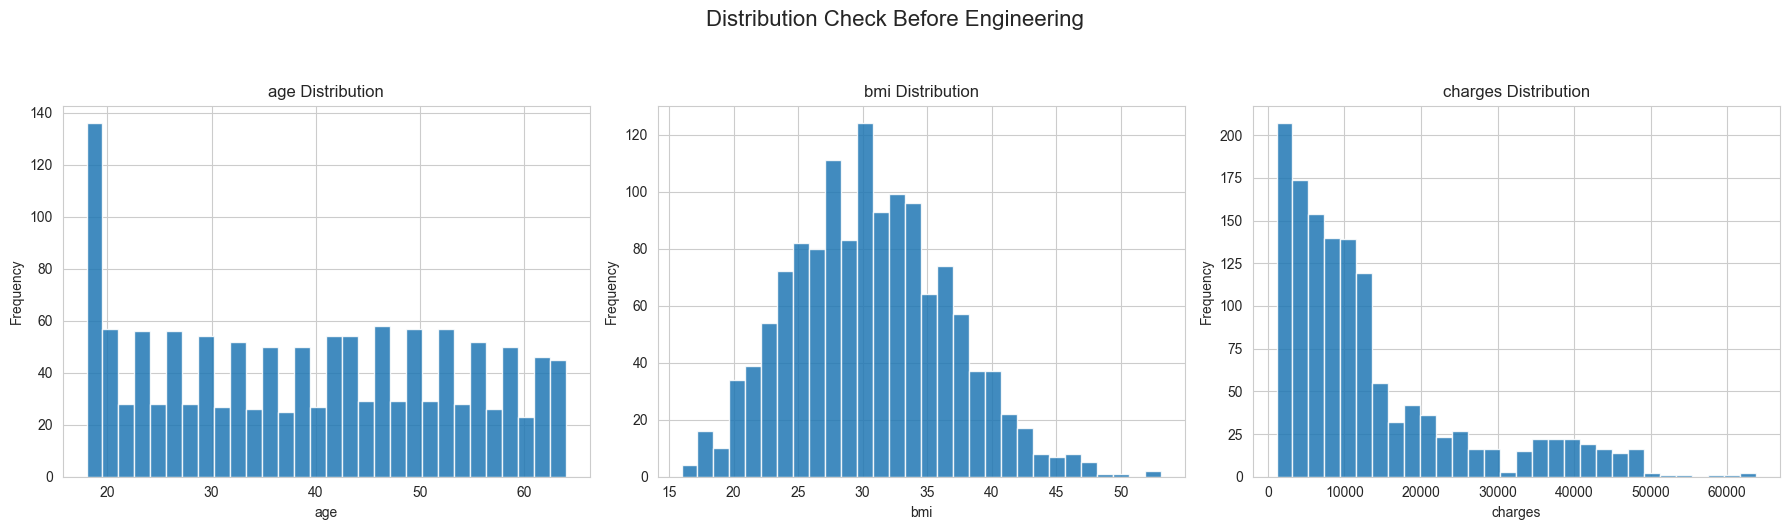

In [7]:
# Check distributions of important numerical columns

important_numeric_cols = ["age", "bmi", "charges"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(important_numeric_cols):
    axes[i].hist(df_clean[col], bins=30, edgecolor="white", alpha=0.85)
    axes[i].set_title(f"{col} Distribution")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.suptitle("Distribution Check Before Engineering", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

In [8]:
# Check numerical summary after duplicate removal

df_clean[important_numeric_cols].describe().round(2)

,age,bmi,charges
count,1337.00,1337.00,1337.00
mean,39.22,30.66,13279.12
std,14.04,6.10,12110.36
min,18.00,15.96,1121.87
25%,27.00,26.29,4746.34
50%,39.00,30.40,9386.16
75%,51.00,34.70,16657.72
max,64.00,53.13,63770.43


### Observation

The dataset is now cleaned by removing the duplicate row.

From the distribution check:

- `age` values are within a valid range.
- `bmi` values are reasonable, although some high BMI values exist.
- `charges` is right-skewed, meaning most customers have lower insurance charges while fewer customers have very high charges.

This cleaned dataset is now ready for feature engineering.

## 4. Feature Engineering

Feature engineering is the process of creating new useful features from existing columns.

Based on the EDA findings, we create the following new features:

- `bmi_category`: groups BMI values into health-related BMI categories
- `age_group`: groups customers into age ranges
- `smoker_obese`: identifies customers who are both smokers and obese

These engineered features can help the machine learning model understand patterns more clearly.

In [9]:
# Create new engineered features using the cleaned dataset

df_feat = create_features(df_clean)

# Identify newly created columns
new_cols = [col for col in df_feat.columns if col not in df_clean.columns]

print(f"New features created: {new_cols}")

# Display first 5 rows
df_feat.head()

New features created: ['bmi_category', 'age_group', 'smoker_obese']


,age,sex,bmi,children,smoker,region,charges,bmi_category,age_group,smoker_obese
0,19,female,27.900,0,yes,southwest,16884.92400,overweight,young,0
1,18,male,33.770,1,no,southeast,1725.55230,obese,young,0
2,28,male,33.000,3,no,southeast,4449.46200,obese,young,0
3,33,male,22.705,0,no,northwest,21984.47061,normal,middle,0
4,32,male,28.880,0,no,northwest,3866.85520,overweight,middle,0


### Engineered Feature Explanation

The new features were created for the following reasons:

- `bmi_category` helps convert BMI values into meaningful groups such as normal, overweight, and obese.
- `age_group` helps separate customers into age-based categories.
- `smoker_obese` captures the interaction between smoking status and obesity.

The `smoker_obese` feature is especially important because the EDA showed that smokers with high BMI values usually have much higher insurance charges.

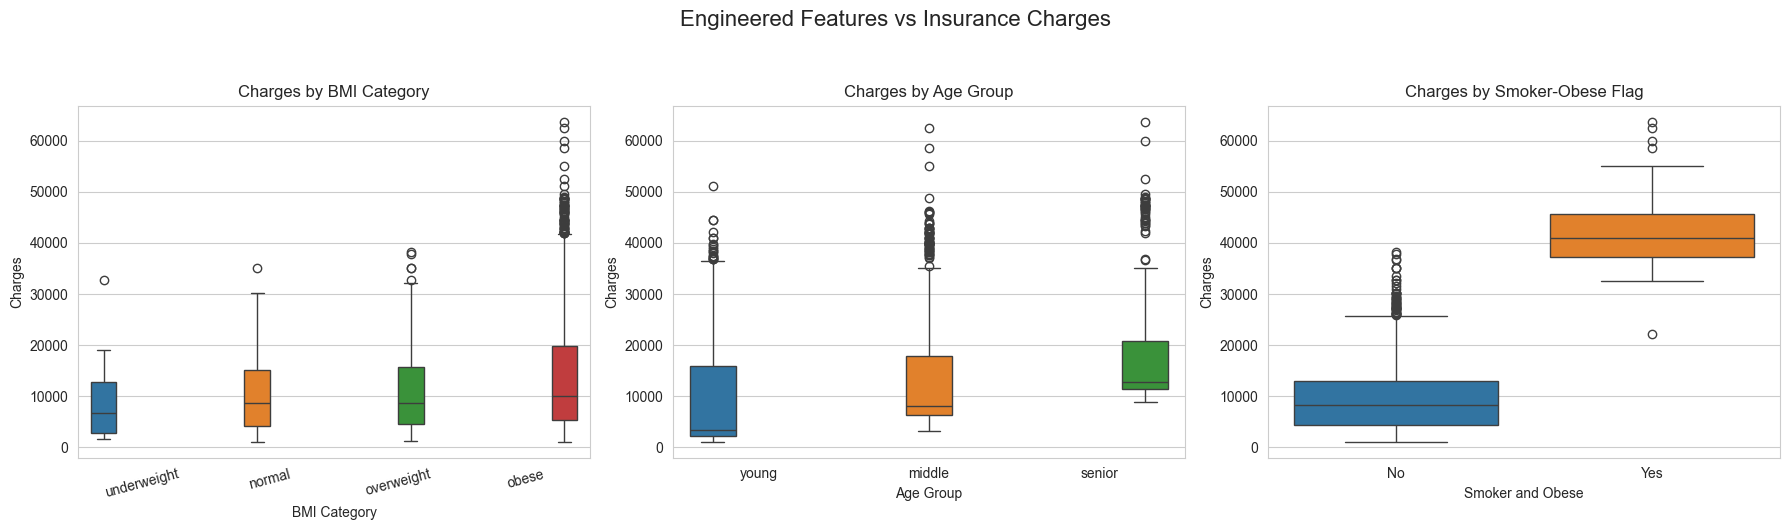

In [10]:
# Visualize engineered features against insurance charges

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Charges by BMI category
sns.boxplot(
    data=df_feat,
    x="bmi_category",
    y="charges",
    hue="bmi_category",
    order=["underweight", "normal", "overweight", "obese"],
    ax=axes[0],
    legend=False
)
axes[0].set_title("Charges by BMI Category")
axes[0].set_xlabel("BMI Category")
axes[0].set_ylabel("Charges")
axes[0].tick_params(axis="x", rotation=15)

# Charges by age group
sns.boxplot(
    data=df_feat,
    x="age_group",
    y="charges",
    hue="age_group",
    order=["young", "middle", "senior"],
    ax=axes[1],
    legend=False
)
axes[1].set_title("Charges by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Charges")

# Charges by smoker-obese feature
sns.boxplot(
    data=df_feat,
    x="smoker_obese",
    y="charges",
    hue="smoker_obese",
    ax=axes[2],
    legend=False
)
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["No", "Yes"])
axes[2].set_title("Charges by Smoker-Obese Flag")
axes[2].set_xlabel("Smoker and Obese")
axes[2].set_ylabel("Charges")

plt.suptitle("Engineered Features vs Insurance Charges", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

In [11]:
# Summary of charges by smoker_obese feature

smoker_obese_summary = (
    df_feat.groupby("smoker_obese")["charges"]
    .agg(["mean", "median", "count"])
    .round(2)
)

smoker_obese_summary

,mean,median,count
smoker_obese,,,
0,9839.16,8338.75,1192
1,41557.99,40904.20,145


### Observation

The engineered features provide useful additional information:

- Customers in older age groups generally have higher insurance charges.
- Obese customers tend to have higher charges than customers in lower BMI categories.
- The `smoker_obese` feature shows a clear difference in charges.

Customers who are both smokers and obese have much higher average charges compared to other customers. This confirms that the `smoker_obese` interaction feature is useful for model building.

## 5. Run the Full Pipeline

In this section, we apply the full preprocessing pipeline to the cleaned dataset.

The preprocessing pipeline performs the following steps:

1. Creates engineered features
2. Converts categorical variables into numerical format using one-hot encoding
3. Prepares the final dataset for machine learning model building

The processed dataset will contain only numerical columns, which are required by most machine learning algorithms.

In [12]:
# Run the full preprocessing pipeline using the cleaned dataset

df_processed = preprocess_data(df_clean)

print(f"Processed dataset shape: {df_processed.shape}")
print(f"Missing values: {df_processed.isnull().sum().sum()}")

df_processed.head()

Processed dataset shape: (1337, 15)
Missing values: 0


,age,bmi,children,charges,smoker_obese,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_normal,bmi_category_overweight,bmi_category_obese,age_group_middle,age_group_senior
0,19,27.900,0,16884.92400,0,0,1,0,0,1,0,1,0,0,0
1,18,33.770,1,1725.55230,0,1,0,0,1,0,0,0,1,0,0
2,28,33.000,3,4449.46200,0,1,0,0,1,0,0,0,1,0,0
3,33,22.705,0,21984.47061,0,1,0,1,0,0,1,0,0,1,0
4,32,28.880,0,3866.85520,0,1,0,1,0,0,0,1,0,1,0


## 6. Sanity Checks & Save

Before saving the final cleaned dataset, we perform basic sanity checks.

These checks confirm that:

- There are no missing values
- The target column `charges` is still available
- The final dataset contains the expected number of rows after duplicate removal

After the checks pass, the processed dataset is saved as `insurance_cleaned.csv` inside the `data` folder.

In [13]:
# Perform sanity checks

assert df_processed.isnull().sum().sum() == 0
assert "charges" in df_processed.columns
assert df_processed.shape[0] == df_clean.shape[0]

print("All checks passed.")

All checks passed.


In [14]:
# Save the processed dataset

df_processed.to_csv("../data/insurance_cleaned.csv", index=False)

print(
    f"Saved ../data/insurance_cleaned.csv "
    f"({df_processed.shape[0]} rows, {df_processed.shape[1]} columns)"
)

Saved ../data/insurance_cleaned.csv (1337 rows, 15 columns)


## 7. Data Cleaning and Feature Engineering Conclusion

The data cleaning and feature engineering stage is now complete.

Completed tasks:

- Checked missing values
- Identified and removed 1 duplicate row
- Created new features: `bmi_category`, `age_group`, and `smoker_obese`
- Encoded categorical variables using one-hot encoding
- Verified that the final processed dataset has no missing values
- Saved the cleaned dataset as `insurance_cleaned.csv`

The cleaned dataset is now ready for machine learning model training in the next notebook.